# Introducción

Al tratarse de un problema de clasificación se probaran dos modelos con diferentes enfoques para cada uno.

**LogisticRegression**
* Ajuste de umbrales
* pesos de clase (class_weight)
* Sobremuestreo.

**RendomForestClassifier**


# Librerías y cargado de datos

## Librerías

In [1]:
import warnings

import sys
import os

sys.path.append(os.path.join('../src'))
import funciones_personales as fp

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.utils import shuffle
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, roc_auc_score, classification_report, roc_curve, precision_recall_curve, precision_recall_fscore_support

## Importación y relevancia de datos

In [12]:
df = pd.read_csv('../data/Churn.csv')

Primer preprocesamiento realizado:

* Sustituir los faltantes en tenure por 0.
* Sustituir 'Female'y 'Male' por 0 y 1.
* Usar EHO para Geaography (France, Spain, Germany) ya que no tienen un orden ordinal (de importancia entre ellos).

In [14]:
# reemplaza los valores nulos por 0 en la columna Tenure
df['Tenure'] = df['Tenure'].fillna(0)
# Cambia 'Gender' a binario
df['Gender'] = df['Gender'].map({'Male':1, 'Female':0} )
# Crea los índices de etiqueta EOF para Geography
geo_dummies = pd.get_dummies(df['Geography'], drop_first=True, prefix='Geography')
# junta los dummies con el df original
df = pd.concat([df, geo_dummies], axis=1)

Determinación de variables (columnas) que realmente afectan a la predicción.

* El índice en el que se encuentra la cadena de datos no afecta en la descisión de un cliente de quedarse o irse.
* El identificador único de cliente no afecta en la descisión de un cliente de quedarse o irse.
* El apellido del cliente no afecta en la descisión de un cliente de quedarse o irse.

In [16]:
# Analicemos las correlaciones con la variable objetivo
print("Correlación con Exited:")
print(f"RowNumber: {df['RowNumber'].corr(df['Exited']):.4f}")
print(f"CustomerId: {df['CustomerId'].corr(df['Exited']):.4f}")
# Análisis de apellidos
surname_churn = df.groupby('Surname')['Exited'].agg(['count', 'mean']).sort_values('mean', ascending=False)
print("Top 10 apellidos con mayor tasa de churn:")
print(surname_churn.head(10))
# Veamos algunos ejemplos de apellidos por país
print("Ejemplos de apellidos por país:")
for country in df['Geography'].unique():
    print(f"\n{country}:")
    apellidos_pais = df[df['Geography'] == country]['Surname'].value_counts().head(5)
    print(apellidos_pais)

# Crear una tabla cruzada entre apellidos y geografía
apellido_geografia = pd.crosstab(df['Surname'], df['Geography'])
# Mostrar apellidos que aparecen en múltiples países
apellidos_multiples = apellido_geografia[(apellido_geografia > 0).sum(axis=1) > 1]
print(f"Apellidos que aparecen en múltiples países: {len(apellidos_multiples)}")

Correlación con Exited:
RowNumber: -0.0166
CustomerId: -0.0062
Top 10 apellidos con mayor tasa de churn:
           count  mean
Surname               
Zarate         1   1.0
Yost           1   1.0
Aikenhead      1   1.0
Yoo            1   1.0
Yewen          1   1.0
Yefimov        1   1.0
Yeates         1   1.0
Yamamoto       1   1.0
Wynn           1   1.0
Woodhouse      1   1.0
Ejemplos de apellidos por país:

France:
Surname
Smith       23
Genovese    15
Maclean     15
Yeh         15
Fang        14
Name: count, dtype: int64

Spain:
Surname
Ma          11
Scott       10
Johnson      9
McKay        9
Mitchell     9
Name: count, dtype: int64

Germany:
Surname
Martin    11
Walker    11
Shen       9
Wang       8
Miller     8
Name: count, dtype: int64
Apellidos que aparecen en múltiples países: 1181


Parece que Surname es un proxy de la variable Geography por lo que se eliminará para el modelo.

Por lo tanto, las columnas relevantes para el modelo, antes de revisar ponderaciones y segmentar los datos son:
['CreditScore','Gender', 'Age', 'Tenure', 'Balance', NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited', Geography_Germany', 'Geography_Spain']

In [17]:
# Obtiene las columnas relevantes para el modelo antes de dividir en features y target.
df_trimd = df[['CreditScore','Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited', 'Geography_Germany', 'Geography_Spain']]
print(df_trimd.shape)

(10000, 12)


# Segmentación de datos en 70%, 15%, 15%
Se elige este porcentaje de segmentación porque:

1. Maximiza los datos de entrenamiento

* Teniendo 10,000 registros, 70% equivalen a 7,000 muestras para entrenar vs 6,000 con 60%
* Más datos de entrenamiento generalmente resultan en modelos más robustos
* Especialmente importante cuando existe desequilibrio de clases, como en este caso: 79.63% vs 20.37%

2. Conjuntos de validación y prueba suficientes

* 15% (1,500 registros) es suficiente para validación confiable
* 15% (1,500 registros) es adecuado para prueba final
* Con 20-20, se tendrían conjuntos más grandes pero sacrificando entrenamiento

3. Estabilidad estadística

* 1,500 registros por conjunto dan estimaciones estadísticamente estables
* Para este caso con ~300 casos de churn por conjunto (20.37%), es suficiente para métricas confiables.

## Distribución del target (dataset completo)

In [18]:
# Veamos la distribución de churn
print("Distribución de Exited:")
print(df_trimd['Exited'].value_counts())
print("\nPorcentajes:")
print(df_trimd['Exited'].value_counts(normalize=True) * 100)

Distribución de Exited:
Exited
0    7963
1    2037
Name: count, dtype: int64

Porcentajes:
Exited
0    79.63
1    20.37
Name: proportion, dtype: float64


Se decide usar `stratify` al segmentar los datos en train, valid y test, para que cada conjunto mantenga la proporción original de target del dataset completo.

In [19]:
# Crea los conjuntos features y target
features = df_trimd.drop('Exited', axis=1)
target = df_trimd['Exited']

# Primera división: 85% (train+test) vs 15% (validation)
features_all, features_valid, target_all, target_valid = train_test_split(
    features, target, 
    test_size=0.15, 
    random_state=54321,
    stratify=target  # ¡Esto es clave!
)
# Segunda división: 70% train vs 15% test (del 85% restante)
# 15/85 ≈ 0.176 para obtener 15% del total
features_train, features_test, target_train, target_test = train_test_split(
    features_all, target_all, 
    test_size=0.176,  # 15/85 = 0.176
    random_state=54321,
    stratify=target_all  # ¡También aquí!
)

## Análisis de Combinación de datos binarios

**Significados para el banco de los componentesde la matriz de confusión:**

Verdaderos Negativos (TN) - "Acierto tranquilo"

* Qué es: Clientes que NO se van (N) y predecimos correctamente (T)
* Para el banco: ✅ Perfecto - no gastamos recursos innecesarios
* Ejemplo: Cliente satisfecho que sigue usando sus servicios

Verdaderos Positivos (TP) - "Salvamos al cliente"

* Qué es: Clientes que SÍ se van (P) y predecimos correctamente (T)
* Para el banco: ✅ ¡Excelente! Podemos actuar para retenerlos
* Ejemplo: Detectamos a tiempo que Juan está insatisfecho y le ofrecemos beneficios

Falsos Positivos (FP) - "Falsa alarma costosa"

* Qué es: El modelo dice 1 (se va el cliente "P"). En realidad el cliente se queda
* Para el banco: ⚠️ Gastamos dinero en retención innecesaria
* Ejemplo: Le damos descuentos a María que nunca pensó irse

Falsos Negativos (FN) - "El error más costoso"

* Qué es: El modelo predice 0 (Cliente se queda) pero, el cliente se vá (T=1)
* Para el banco: ❌ ¡Perdemos al cliente sin intentar retenerlo!
* Ejemplo: Carlos se va al banco competidor y no hicimos nada

Bajo este contexto, es mejor para el banco tener algún numero de falsos positivos afectando la presición, pero acaparando el mayor porcentaje de detecciones de clientes que se van disminuyendo los FN del umbral para aumentar el recall.

Por tanto, en este análisis priorizaremos maximizar el recall (detectar la mayor cantidad de clientes que se van) aunque esto implique una precisión menor (más falsas alarmas).

# Modelo base regresión logística (sin considerar desequilibrio)

Reporte de clasificación en validación (Logistic Regression Baseline):
              precision    recall  f1-score   support

           0       0.80      0.97      0.88      1194
           1       0.39      0.06      0.11       306

    accuracy                           0.79      1500
   macro avg       0.59      0.52      0.49      1500
weighted avg       0.72      0.79      0.72      1500

F1 Score (Logistic Regression Baseline): 0.1070
AUC-ROC (Logistic Regression Baseline): 0.6740


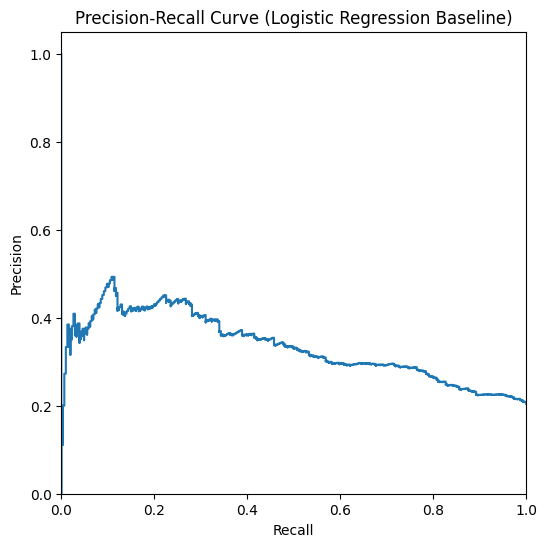

   threshold  precision    recall        f1
0       0.00   0.204000  1.000000  0.338870
1       0.05   0.207880  1.000000  0.344207
2       0.10   0.224655  0.905229  0.359974
3       0.15   0.259182  0.807190  0.392375
4       0.20   0.296460  0.656863  0.408537
5       0.25   0.332589  0.486928  0.395225
6       0.30   0.358804  0.352941  0.355848
7       0.35   0.411483  0.281046  0.333981
8       0.40   0.425532  0.196078  0.268456
9       0.45   0.415730  0.120915  0.187342


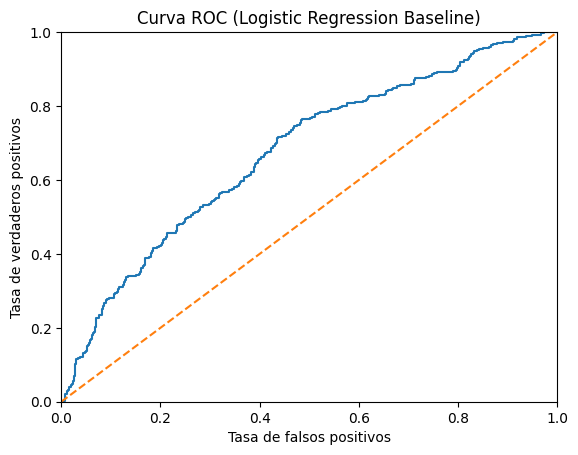

In [20]:
log_reg_base = LogisticRegression(random_state=54321, solver='liblinear')
# Entrenamos el conjunto de datos
log_reg_base.fit(features_train, target_train)

fp.roc_plot_enhanced(log_reg_base, features_valid, target_valid, "Logistic Regression Baseline")

## Conclusión específica del modelo base
**F1 score**: 0.1070
Aún lejos de la meta del proyecto (0.59). 0.483 para la meta
**AUC-ROC** (Logistic Regression Baseline): 0.6740. por encima del 50% pero aún le falta pilumiento
**No se recomienda usar este modelo**

# Regresión logística modificando umbrales manualmente
Se prueba con diferentes umbrales y se elegirá el umbral para el cual el recall sea mayor.

In [21]:
# Probar diferentes umbrales
thresholds_test = np.arange(0.1, 0.5, 0.05)
probabilities_one_valid = log_reg_base.predict_proba(features_valid)[:, 1]
results = []
for threshold in thresholds_test:
    # Hacer predicciones con el nuevo umbral
    preds_threshold = (probabilities_one_valid >= threshold).astype(int)
    
    # Calcular métricas
    precision, recall, f1, _ = precision_recall_fscore_support(
        target_valid, preds_threshold, average='binary'
    )
    
    results.append({
        'threshold': threshold,
        'precision': precision,
        'recall': recall,
        'f1': f1
    })

# Mostrar resultados
results_df = pd.DataFrame(results)
print(results_df)


   threshold  precision    recall        f1
0       0.10   0.224655  0.905229  0.359974
1       0.15   0.259182  0.807190  0.392375
2       0.20   0.296460  0.656863  0.408537
3       0.25   0.332589  0.486928  0.395225
4       0.30   0.358804  0.352941  0.355848
5       0.35   0.411483  0.281046  0.333981
6       0.40   0.425532  0.196078  0.268456
7       0.45   0.415730  0.120915  0.187342


## Conclusión Específica de regresión logística con umbrales manuales: 
El umbral 0.10 muestra un recall de: 0.905229, una precisión de: 0.224655 y un valor F1 de: 0.359974 (Aún no es suficiente, el proyecto pide: 0.59)
Aunque mejor que el anterior **No se recomienda usar este modelo**

# Regresión logística con pesos de clase (class_weight)

Reporte de clasificación en validación (Logistic Regression con Class Weight):
              precision    recall  f1-score   support

           0       0.89      0.67      0.76      1194
           1       0.34      0.67      0.45       306

    accuracy                           0.67      1500
   macro avg       0.61      0.67      0.61      1500
weighted avg       0.78      0.67      0.70      1500

F1 Score (Logistic Regression con Class Weight): 0.4513
AUC-ROC (Logistic Regression con Class Weight): 0.7237


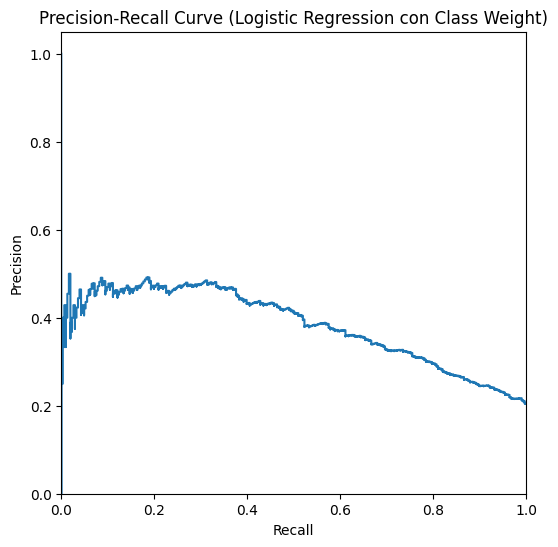

   threshold  precision    recall        f1
0       0.00   0.204000  1.000000  0.338870
1       0.05   0.204000  1.000000  0.338870
2       0.10   0.204136  1.000000  0.339058
3       0.15   0.205111  0.996732  0.340212
4       0.20   0.212185  0.990196  0.349481
5       0.25   0.220643  0.964052  0.359099
6       0.30   0.235102  0.941176  0.376225
7       0.35   0.252788  0.888889  0.393632
8       0.40   0.275190  0.830065  0.413344
9       0.45   0.309429  0.761438  0.440038


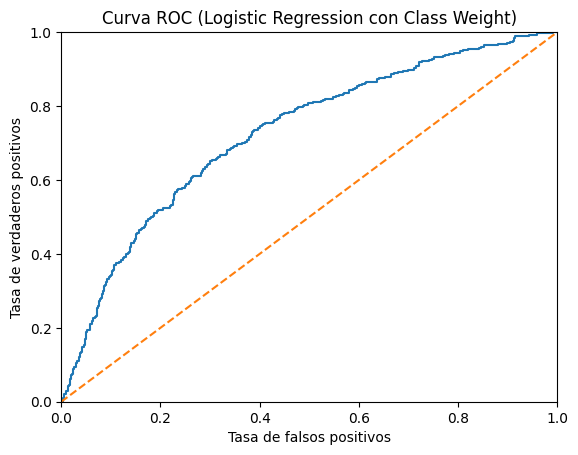

In [22]:
log_reg_weight = LogisticRegression(
    random_state=54321, 
    solver='liblinear',
    class_weight='balanced'
)
# Entrenar el modelo
log_reg_weight.fit(features_train, target_train)

# Evaluar con nuestra función
fp.roc_plot_enhanced(log_reg_weight, features_valid, target_valid, "Logistic Regression con Class Weight")

## Conclusión Especifica de regresión logística con class_weight
El modelo de regresión logística con pesos balanceados ya calcula un umbral óptimo, por ello cuando hacemos pruebas de umbrales los resultados son peores.
**Modelo de regresión logística con pesos balanceados: 
**F1**: 0.4513 Aun no cumple con la meta pero está cerca sólo 0.1387 para alcanzar la meta.
**AUC-ROC**: 0.7237. El mejor hasta el momento.
Se recomienda su uso sólo si es estrictamente necesario utilizar un modelo de regresión logística.

# Regresión logística: Sobremuestreo

In [23]:
# condiciones actuales y búsqueda de repeat para aplicar a la función upsamble
# Verificar distribución actual
print("Distribución actual:")
print(f"Clase 0 (No churn): {sum(target_train == 0)}")
print(f"Clase 1 (Churn): {sum(target_train == 1)}")

# Calcular repeat para balance 50-50
n_majority = sum(target_train == 0)
n_minority = sum(target_train == 1)
repeat_for_balance = n_majority // n_minority

print(f"\nPara balance 50-50, repeat = {repeat_for_balance}")
print(f"Esto daría: {n_minority * repeat_for_balance} ejemplos de clase 1")

# Aplicar sobremuestreo con repeat = 3
features_train_upsampled, target_train_upsampled = fp.upsample(
    features_train, 
    target_train, 
    repeat=3
)

# Verificar la nueva distribución
print()
print("Distribución después del sobremuestreo:")
print(f"Clase 0: {sum(target_train_upsampled == 0)}")
print(f"Clase 1: {sum(target_train_upsampled == 1)}")
print(f"Total: {len(target_train_upsampled)}")
print(f"Nueva proporción de churn: {sum(target_train_upsampled == 1) / len(target_train_upsampled):.3f}")

Distribución actual:
Clase 0 (No churn): 5578
Clase 1 (Churn): 1426

Para balance 50-50, repeat = 3
Esto daría: 4278 ejemplos de clase 1

Distribución después del sobremuestreo:
Clase 0: 5578
Clase 1: 4278
Total: 9856
Nueva proporción de churn: 0.434


/home/alienfibio_linux/miniconda3/envs/m_learning/lib/python3.9/site-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Reporte de clasificación en validación (Logistic Regression + upsample (repeat=3)):
              precision    recall  f1-score   support

           0       0.87      0.77      0.81      1194
           1       0.37      0.53      0.44       306

    accuracy                           0.72      1500
   macro avg       0.62      0.65      0.63      1500
weighted avg       0.76      0.72      0.74      1500

F1 Score (Logistic Regression + upsample (repeat=3)): 0.4370
AUC-ROC (Logistic Regression + upsample (repeat=3)): 0.7036


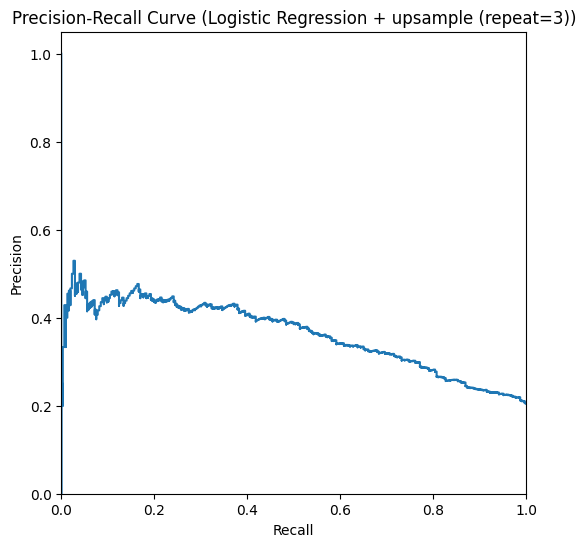

   threshold  precision    recall        f1
0       0.00   0.204000  1.000000  0.338870
1       0.05   0.204000  1.000000  0.338870
2       0.10   0.204545  1.000000  0.339623
3       0.15   0.212482  0.990196  0.349885
4       0.20   0.219837  0.970588  0.358479
5       0.25   0.231980  0.915033  0.370126
6       0.30   0.247672  0.869281  0.385507
7       0.35   0.273836  0.807190  0.408940
8       0.40   0.308966  0.732026  0.434530
9       0.45   0.334507  0.620915  0.434783


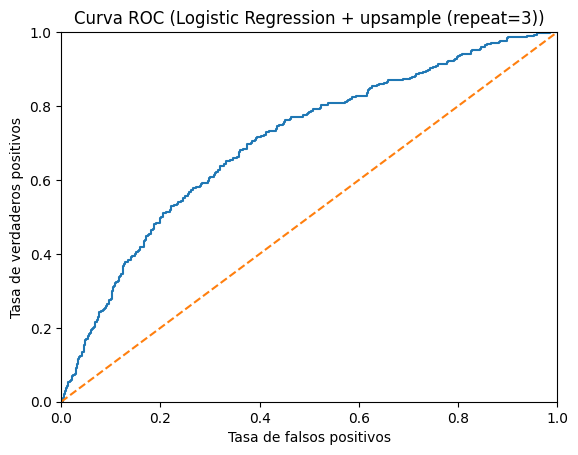

In [30]:
log_reg_upsample = LogisticRegression(random_state=54321)
log_reg_upsample.fit(features_train_upsampled, target_train_upsampled)

# Usar función optimizada para evaluación completa
fp.roc_plot_enhanced(
    log_reg_upsample, 
    features_valid, 
    target_valid, 
    model_name="Logistic Regression + upsample (repeat=3)")

## Conclusión específica de regresión logística con sobremuestreo:
F1 Score (Logistic Regression + upsample (repeat=3)): 0.4370: Mejor que el modelo base pero peor que el modelo con pesos balanceados.
AUC-ROC (Logistic Regression + upsample (repeat=3)): 0.7036: Mismo resultado, se encuentra entre el modelo base y el de pesos balanceados.

# Conclusiones de Modelos de Regresión Logística

**Resumen de Resultados:**

Modelo Base (sin tratamiento de desequilibrio)
* F1 Score: 0.1070
* AUC-ROC: 0.6740
* Recall muy bajo (0.06) - no detecta bien el churn

Modelo con Class Weight 'balanced'
* F1 Score: 0.4513
* AUC-ROC: 0.7237
* Mejor balance entre precisión y recall

Modelo con Sobremuestreo (repeat=3)
* F1 Score: 0.4370
* AUC-ROC: 0.7036
* Ligeramente inferior al class_weight

**Mejor Modelo de Regresión Logística:**

El modelo con class_weight='balanced' es el ganador con F1=0.4513 y AUC-ROC=0.7237. Aún no es suficiente para cumplir la meta

# RandomForestClassifier modelo base con hiperparámetros
* Se utilizará una función que encuentra el mejor modelo (mayor F1) variando hiperparámetros (n_estimators y max_depth).
* Se utilizará el modelo con el F1 más alto para aplicar en él las técnicas de balanceo.

## Justificación de hiperparámetros:
Justificación de los rangos:
n_estimators (50-200):
* 50-100: Rango típico para datasets medianos
* 100-200: Para mayor estabilidad sin costo computacional excesivo
* Paso de 25: range(50, 225, 25) → [50, 75, 100, 125, 150, 175, 200]

max_depth (3-15):
* 3-5: Modelos conservadores, menos overfitting
* 6-10: Rango óptimo para la mayoría de problemas
* 11-15: Para capturar patrones complejos sin sobreajustar

Se utilizará la función con: 
* `min_depth=3`: Muy shallow puede ser insuficiente
* `max_depth=15`: Evitar overfitting con dataset de 7K
* `min_est=50`: Empezar con más árboles para estabilidad
* `max_est=200`: Suficiente para convergencia
* `step_est=25`: Buen balance entre precisión y eficiencia

In [24]:
best_rf_base_model, best_base_n_est, best_base_depth, best_base_f1 = fp.forest_classif_comb_f1(
    features_train, 
    target_train, 
    features_valid, 
    target_valid,
    min_depth=3, 
    max_depth=15, 
    min_est=50, 
    max_est=200, 
    step_est=25
)

n_estimators = 50, max_depth = 3, F1 = 0.1824
n_estimators = 50, max_depth = 4, F1 = 0.3536
n_estimators = 50, max_depth = 5, F1 = 0.5118
n_estimators = 50, max_depth = 6, F1 = 0.5455
n_estimators = 50, max_depth = 7, F1 = 0.5607
n_estimators = 50, max_depth = 8, F1 = 0.5670
n_estimators = 50, max_depth = 10, F1 = 0.5702
n_estimators = 50, max_depth = 11, F1 = 0.5702
n_estimators = 50, max_depth = 13, F1 = 0.5816
n_estimators = 50, max_depth = 14, F1 = 0.5853
n_estimators = 50, max_depth = 15, F1 = 0.5875
n_estimators = 75, max_depth = 15, F1 = 0.5892
n_estimators = 100, max_depth = 13, F1 = 0.5912
Mejor modelo: n_estimators = 100, max_depth = 13, F1 = 0.5912


El mejor modelo base se encontró a los 100 estimadores con profundidad de 13 y F1 de .5912.
Se realizará una búsqueda más fina alrededor de estos hiperpatrámetros con la finalidad de:
* Asegurar el óptimo local alrededor de n_estimators=100, max_depth=13
* Crear un buffer por encima de F1=0.59 antes del balanceo
* Tener margen de seguridad si el balanceo afecta ligeramente el F1

In [25]:
# Búsqueda afinada alrededor del mejor modelo
best_rf_fine_model, best_fine_n_est, best_fine_depth, best_fine_f1 = fp.forest_classif_comb_f1(
    features_train,
    target_train, 
    features_valid,
    target_valid,
    min_depth=11,      # Alrededor de 13
    max_depth=16,      # Explorar un poco más
    min_est=80,        # Alrededor de 100  
    max_est=120,       # Rango conservador
    step_est=10        # Más granular
)

n_estimators = 80, max_depth = 11, F1 = 0.5708
n_estimators = 80, max_depth = 12, F1 = 0.5714
n_estimators = 80, max_depth = 13, F1 = 0.5840
n_estimators = 80, max_depth = 15, F1 = 0.5870
n_estimators = 90, max_depth = 13, F1 = 0.5895
n_estimators = 100, max_depth = 13, F1 = 0.5912
n_estimators = 120, max_depth = 13, F1 = 0.5941
Mejor modelo: n_estimators = 120, max_depth = 13, F1 = 0.5941


Se obtuvo un buffer de .0041 al usar estimadores=120 y max_depth=13, obteniendo F1 de 0.5941
Se decide continuar con este modelo como base y proceder a realizar el balanceo correspondiente con los hiperparámetros:

Reporte de clasificación en validación (RandomForestClassifier est:120, depth:13):
              precision    recall  f1-score   support

           0       0.88      0.97      0.92      1194
           1       0.83      0.46      0.59       306

    accuracy                           0.87      1500
   macro avg       0.85      0.72      0.76      1500
weighted avg       0.87      0.87      0.86      1500

F1 Score (RandomForestClassifier est:120, depth:13): 0.5941
AUC-ROC (RandomForestClassifier est:120, depth:13): 0.8375


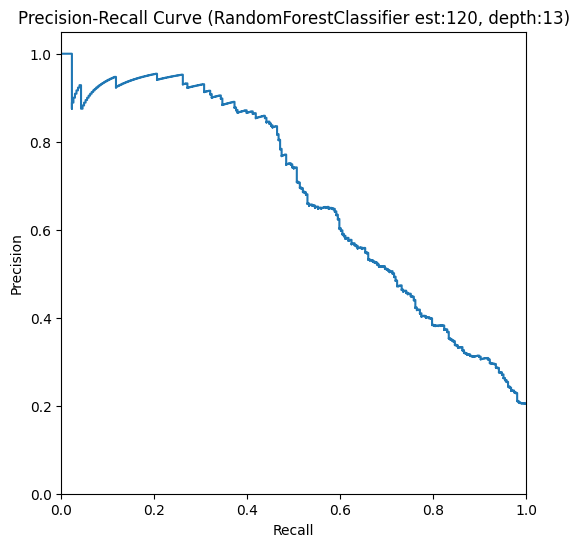

   threshold  precision    recall        f1
0       0.00   0.204000  1.000000  0.338870
1       0.05   0.264786  0.950980  0.414235
2       0.10   0.326733  0.862745  0.473968
3       0.15   0.398361  0.794118  0.530568
4       0.20   0.464730  0.732026  0.568528
5       0.25   0.529716  0.669935  0.591631
6       0.30   0.578947  0.611111  0.594595
7       0.35   0.649057  0.562092  0.602452
8       0.40   0.700893  0.513072  0.592453
9       0.45   0.779570  0.473856  0.589431


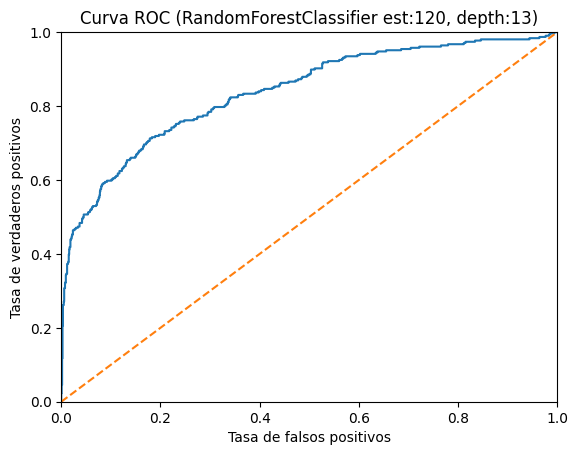

In [26]:
rand_for_base = RandomForestClassifier(max_depth=13, n_estimators=120, random_state=54321)
rand_for_base.fit(features_train, target_train)

# Usar función optimizada para evaluación completa
fp.roc_plot_enhanced(
    rand_for_base, 
    features_valid, 
    target_valid, 
    model_name="RandomForestClassifier est:120, depth:13")

## Conclusión específica de Random Forest base con hiperparámetros:
**F1 Score**: 0.5941
**AUC-ROC**: 0.8375
**Recall**: 0.46
**Precisión**: 0.83

Aunque este modelo ya cumple con la meta de F1, el recall para los clientes que se van sigue siendo muy bajo (0.46), sólo detecta el 46% de clientes que se van, no detecta a más de la mitad, eso esta MAL para el negocio.

* Se realizarán pruebas de balanceo con la finalidad de mejorar el recall intentando que no baje el F1. De aquí se determinará cual es el mejor modelo y se probará con el conjunto de test.

# Random Forest con sobremuestreo

Reporte de clasificación en validación (RandomForestClassifier est:120, depth:13, upsampled):
              precision    recall  f1-score   support

           0       0.89      0.92      0.91      1194
           1       0.65      0.57      0.61       306

    accuracy                           0.85      1500
   macro avg       0.77      0.75      0.76      1500
weighted avg       0.84      0.85      0.85      1500

F1 Score (RandomForestClassifier est:120, depth:13, upsampled): 0.6076
AUC-ROC (RandomForestClassifier est:120, depth:13, upsampled): 0.8420


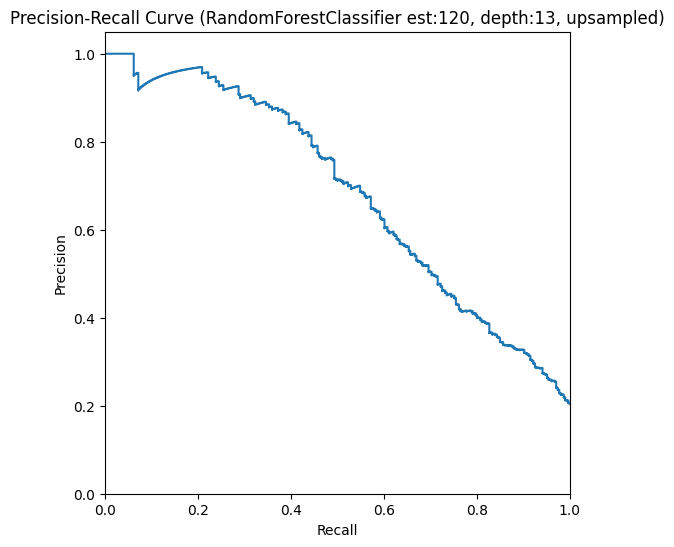

   threshold  precision    recall        f1
0       0.00   0.204000  1.000000  0.338870
1       0.05   0.235759  0.973856  0.379618
2       0.10   0.270950  0.950980  0.421739
3       0.15   0.309735  0.915033  0.462810
4       0.20   0.348993  0.849673  0.494767
5       0.25   0.399023  0.800654  0.532609
6       0.30   0.448343  0.751634  0.561661
7       0.35   0.492135  0.715686  0.583222
8       0.40   0.543243  0.656863  0.594675
9       0.45   0.589506  0.624183  0.606349


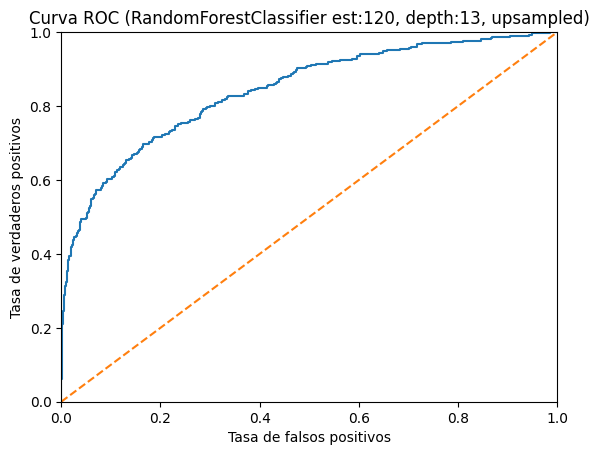

In [27]:
rand_for_upsample = RandomForestClassifier(max_depth=13, n_estimators=120, random_state=54321)
rand_for_upsample.fit(features_train_upsampled, target_train_upsampled)

# Usar función optimizada para evaluación completa
fp.roc_plot_enhanced(
    rand_for_upsample, 
    features_valid, 
    target_valid, 
    model_name="RandomForestClassifier est:120, depth:13, upsampled")

## Conclusión específica de Random Forest con sobremuestreo

**F1 Score:** 0.6076
**AUC-ROC:** 0.8420
**Recall:** 0.57
**Precisión:** 0.65

# Random Forest con Pesos de clase balanced

Reporte de clasificación en validación (RandomForestClassifier est:120, depth:13, class_weight):
              precision    recall  f1-score   support

           0       0.88      0.95      0.91      1194
           1       0.72      0.51      0.59       306

    accuracy                           0.86      1500
   macro avg       0.80      0.73      0.75      1500
weighted avg       0.85      0.86      0.85      1500

F1 Score (RandomForestClassifier est:120, depth:13, class_weight): 0.5939
AUC-ROC (RandomForestClassifier est:120, depth:13, class_weight): 0.8388


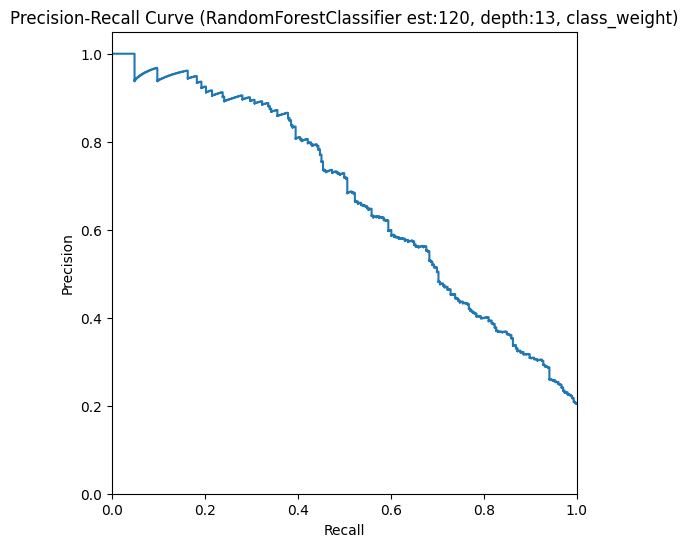

   threshold  precision    recall        f1
0       0.00   0.204000  1.000000  0.338870
1       0.05   0.242028  0.967320  0.387181
2       0.10   0.287425  0.941176  0.440367
3       0.15   0.324423  0.872549  0.472985
4       0.20   0.382398  0.823529  0.522280
5       0.25   0.433333  0.764706  0.553191
6       0.30   0.488636  0.702614  0.576408
7       0.35   0.557951  0.676471  0.611521
8       0.40   0.612795  0.594771  0.603648
9       0.45   0.656126  0.542484  0.593918


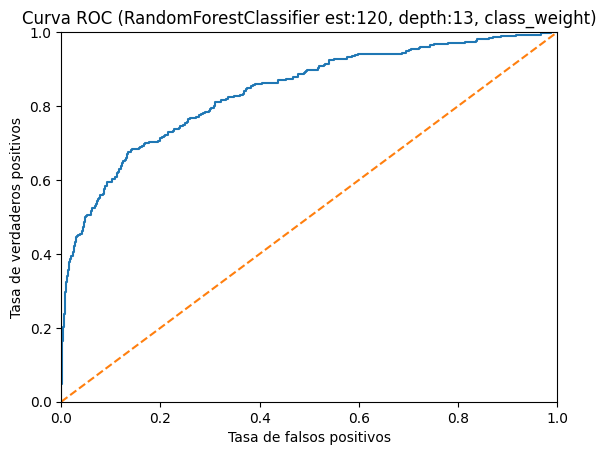

In [28]:
rand_for_weight = RandomForestClassifier(max_depth=13, n_estimators=120, random_state=54321, class_weight='balanced')
rand_for_weight.fit(features_train, target_train)

# Usar función optimizada para evaluación completa
fp.roc_plot_enhanced(
    rand_for_weight, 
    features_valid, 
    target_valid, 
    model_name="RandomForestClassifier est:120, depth:13, class_weight")


## Conclusiones específicas de Random Forest con peso de clases
**F1 Score:** 0.5939
**AUC-ROC:** 0.8388
**Recall:** 0.51
**Precisión:** 0.72

# Conclusión de modelos random forest y elección del modelo final para pruebas con test

**Análisis de resultados para Random Forest:**

Random Forest Base (hiperparámetros optimizados):
- F1: 0.5941 ✅ (cumple meta)
- Recall: 0.46 ❌ (muy bajo para el negocio)
- Precisión: 0.83

Random Forest + Sobremuestreo:
- F1: 0.6076 ✅ (el mejor F1)
- Recall: 0.57 ✅ (mejora significativa)
- Precisión: 0.65

Random Forest + Class Weight:
- F1: 0.5939 (prácticamente igual al base, 0.5941)
- Recall: 0.51 (mejora mínima)
- Precisión: 0.72

Se decide elegir el Random Forest con sobremuestreo por estas razones:

* Mejor F1 Score: 0.6076 > 0.59 (meta cumplida con margen).
* Recall mejorado: 0.57 vs 0.46 del base (24% más clientes detectados).
* Balance óptimo: Mejor trade-off entre precisión y recall.
* Impacto en el negocio: Detecta 57% de clientes que se van vs 46%.

# Prueba del mejor modelo elegido
* Se eligió el modelo Random Forest con sobremuestreo (repeat=3)
* Se realizará la prueba final y se presentarán las conclusiones finales

Reporte de clasificación en validación (RandomForestClassifier est:120, depth:13, + upsample (repeat=3)):
              precision    recall  f1-score   support

           0       0.90      0.90      0.90      1191
           1       0.61      0.61      0.61       305

    accuracy                           0.84      1496
   macro avg       0.76      0.76      0.76      1496
weighted avg       0.84      0.84      0.84      1496

F1 Score (RandomForestClassifier est:120, depth:13, + upsample (repeat=3)): 0.6108
AUC-ROC (RandomForestClassifier est:120, depth:13, + upsample (repeat=3)): 0.8655


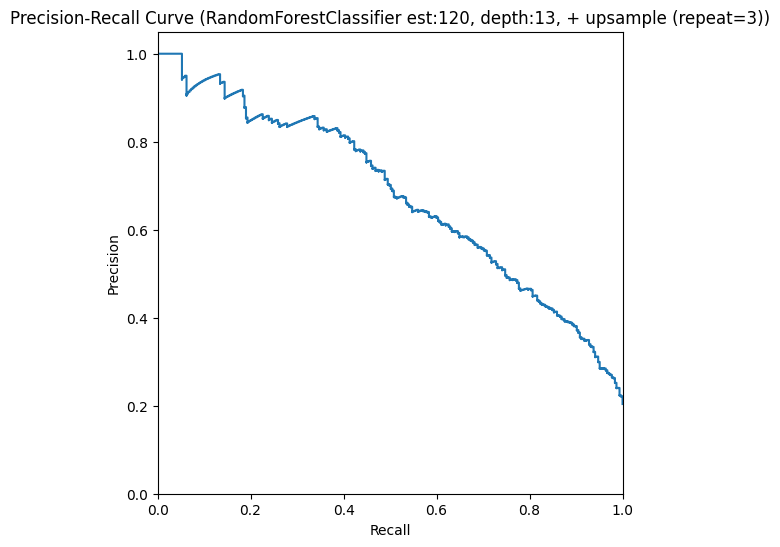

   threshold  precision    recall        f1
0       0.00   0.203877  1.000000  0.338701
1       0.05   0.238583  0.993443  0.384762
2       0.10   0.280418  0.967213  0.434783
3       0.15   0.327231  0.937705  0.485157
4       0.20   0.368000  0.904918  0.523223
5       0.25   0.404946  0.859016  0.550420
6       0.30   0.446237  0.816393  0.577057
7       0.35   0.485294  0.757377  0.591549
8       0.40   0.540943  0.714754  0.615819
9       0.45   0.583090  0.655738  0.617284


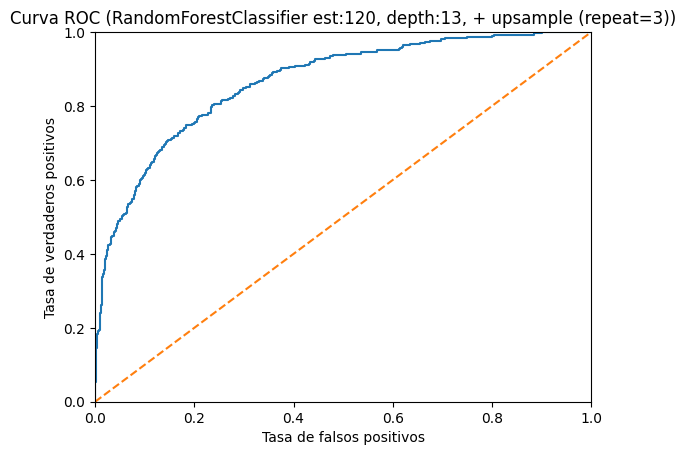

In [29]:
# Usar función optimizada para evaluación completa
fp.roc_plot_enhanced(
    rand_for_upsample, 
    features_test, 
    target_test, 
    model_name="RandomForestClassifier est:120, depth:13, + upsample (repeat=3)")

## Conclusión Específica de prueba final:

**Resultados del test:**

**F1 Score:** 0.6108
**AUC-ROC:** 0.8655
**Recall:** 0.61
**Precisión:** 0.61

**Resultados del conjunto de validación:**

**F1 Score:** 0.6076
**AUC-ROC:** 0.8420
**Recall:** 0.57
**Precisión:** 0.65

* Buena consistencia entre el conjunto de validación y el conjunto de pruebas.
* Supera la meta de 0.59 en F1 y el AUC-ROC es cercano a 1 (0.8655).
* De los clientes que el modelo predice que se irán, el 61% efectivamente se va (precisión), lo que significa costos de retención más eficientes.
* Con los conocimientos adquiridos hasta el momento, este modelo es el mejor.
    * Logistic Regresion
    * Ramdom Forest Regression
    * Manejo de hiperparámetros
    * manejo de balanceo con sobremuestreo, peso de clases y cálculo manual de umbrales.

# Conclusión general
* Beta bank tiene problemas con clientes que están abandonando el negocio. Se propone como solución realizar un modelo que detecte qué clientes son los que pretenden abandonar para poder retenerlos.
* Se probaron dos modelos: Regresión logística y random forest.
    * Regresión Logística:
        * Se toma como base sin modificar.
        * Se investiga manualmente como cambia f1, AUC-ROC, precisión y recall con diferentes umbrales.
        * Se prueba con class_weight='balanced'.
        * Se realiza prueba con sobremuestreo.
    * Random Forest Regression.
        * Se realiza una investigación para elegir los mejores hiperparámetros (estimators y depth) para el modelo base.
        * Se prueba el modelo con sobremuestreo (resultó el elegido)
        * Se prueba con class_weight='balanced'.
* Basados en los parámetros: F1, AUC-ROC, recall y precisión se decide utilizar el modelo: RandomForestClassifier est:120, depth:13, + upsample (repeat=3). ya que es el más destacado y con mejor tradeoff.

Implicaciones para el negocio:

* De los clientes que el modelo predice que se irán, el 61% efectivamente se va (precisión), lo que significa costos de retención más eficientes.
* El negocio debe prestar especial atención en la retención de los clientes predichos y aumentar esfuerzos en los que se encuentre una mayor probabilidad de abandonar.
* Se recomiendan promociones de cashback o gift cards para los clientes con mayor probabilidad de abandonar